# Класифікація тяжкості ДТП (`Severity`): DecisionTree, RandomForest (Spark MLlib)


## 0. Налаштування

Параметри запуску задаються змінними середовища: `TRAIN_FRACTION`, `SPARK_PARALLELISM`, `SPARK_DRIVER_MEMORY`, `SHAP_ROWS`. Планувальник FAIR дозволяє паралельним потокам ділити ресурси Spark.

In [1]:
import os
import sys
import json
import time
import random
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

PROJECT_ROOT = Path.cwd() if (Path.cwd() / "main.py").exists() else Path.cwd().parent
os.chdir(PROJECT_ROOT)
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
from IPython.display import display

from pyspark import StorageLevel
from pyspark.sql import SparkSession, Window, functions as F
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.functions import vector_to_array
from pyspark.ml.classification import DecisionTreeClassifier, RandomForestClassifier
from pyspark.ml.evaluation import Evaluator, BinaryClassificationEvaluator
from pyspark.ml.tuning import CrossValidator, ParamGridBuilder

TASK = "classification"
SEED = 42
TRAIN_FRACTION = float(os.environ.get("TRAIN_FRACTION", "1"))  
PARALLELISM = int(os.environ.get("SPARK_PARALLELISM", "2"))      
FIT_PARALLELISM = int(os.environ.get("SPARK_FIT_PARALLELISM", "1"))  
SHAP_ROWS = int(os.environ.get("SHAP_ROWS", "3000"))
TUNE_ROWS = 80_000
N_FOLDS = 5
N_CANDIDATES = 15
ROC_BINS = 1000
CLASSES = [0, 1, 2, 3]
CLASS_NAMES = [f"Severity {k + 1}" for k in CLASSES]
DATA_DIR = PROJECT_ROOT / "data" / "processed" / TASK
MODELS_DIR = PROJECT_ROOT / "data" / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)
SPARK_TMP = Path(os.environ.get("SPARK_LOCAL_DIR", str(PROJECT_ROOT / "spark-tmp")))

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.max_rows", 300)

spark = (
    SparkSession.builder
    .appName(f"US-Accidents-{TASK}-model-yv")
    .master(os.environ.get("SPARK_MASTER", "local[*]"))
    .config("spark.driver.memory", os.environ.get("SPARK_DRIVER_MEMORY", "16g"))
    .config("spark.driver.host", "localhost")
    .config("spark.ui.port", "4040")
    .config("spark.scheduler.mode", "FAIR")
    .config("spark.sql.shuffle.partitions", "48")
    .config("spark.local.dir", str(SPARK_TMP))
    .config("spark.sql.execution.arrow.pyspark.enabled", "true")
    .config("spark.driver.maxResultSize", "4g")
    .config("spark.ui.showConsoleProgress", "false")
    .config("spark.sql.debug.maxToStringFields", "1000")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")
spark.sparkContext.setCheckpointDir(str(SPARK_TMP / "checkpoints" / TASK))
print(f"Spark {spark.version}, master {spark.sparkContext.master}, parallelism {PARALLELISM} (fit {FIT_PARALLELISM}), "
      f"train fraction {TRAIN_FRACTION}, UI {spark.sparkContext.uiWebUrl}")

/Users/yana.vyklyuk/Documents/GitHub/US-Accidents-spark-project/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/10/26 05:35:54 WARN Utils: Your hostname, MacBook-Pro-Ana-2.local, resolves to a loopback address: 127.0.0.1; using 192.168.68.55 instead (on interface en0)
26/10/26 05:35:54 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/10/26 05:35:55 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/10/26 05:35:55 WARN SparkConf: Note that spark.local.dir will be overridden by the value set by the cluster manager (via SPARK_LOCAL_DIRS in standalone/kubernetes and LOCAL_DIRS in YARN).


26/10/26 05:35:56 WARN Utils: Service 'SparkUI' could not bind on port 4040. Attempting port 4041.


Spark 4.1.1, master local[*], parallelism 2 (fit 1), train fraction 1.0, UI http://localhost:4041


Допоміжні функції: паралельний запуск Spark-задач у потоках, метрики з матриці помилок (один прохід Spark), ROC-AUC через `BinaryClassificationEvaluator`, точки ROC-кривих з гістограми ймовірностей у Spark, графіки.

In [2]:
def run_parallel(fn, keys, workers=None):
    keys = list(keys)
    with ThreadPoolExecutor(max_workers=workers or PARALLELISM) as pool:
        return dict(zip(keys, pool.map(fn, keys)))


def with_probs(pred):
    return pred.select("label", "prediction", vector_to_array("probability").alias("p"))


def confusion(pred, prediction=None):
    prediction = F.col("prediction") if prediction is None else prediction
    cm = np.zeros((len(CLASSES), len(CLASSES)), dtype=np.int64)
    for r in pred.groupBy("label", prediction.alias("pred")).count().collect():
        cm[int(r["label"]), int(r["pred"])] = r["count"]
    return cm


def cm_metrics(cm):
    tp = np.diag(cm).astype(float)
    support, predicted = cm.sum(axis=1), cm.sum(axis=0)
    precision = np.divide(tp, predicted, out=np.zeros_like(tp), where=predicted > 0)
    recall = np.divide(tp, support, out=np.zeros_like(tp), where=support > 0)
    f1 = np.divide(2 * precision * recall, precision + recall, out=np.zeros_like(tp), where=precision + recall > 0)
    out = {"Accuracy": tp.sum() / cm.sum(), "Balanced accuracy": recall.mean()}
    out.update({f"Precision {n}": v for n, v in zip(CLASS_NAMES, precision)})
    out.update({f"Recall {n}": v for n, v in zip(CLASS_NAMES, recall)})
    out.update({"F1 macro": f1.mean(), "F1 weighted": np.average(f1, weights=support)})
    return out


def evaluate(pred):
    pred = with_probs(pred).persist(StorageLevel.MEMORY_AND_DISK)
    cm = confusion(pred)
    auc_eval = BinaryClassificationEvaluator(rawPredictionCol="score", labelCol="is_class", metricName="areaUnderROC")
    auc = np.array([auc_eval.evaluate(pred.select(F.col("p")[k].alias("score"),
                                                  (F.col("label") == k).cast("double").alias("is_class")))
                    for k in CLASSES])
    pred.unpersist()
    out = cm_metrics(cm)
    out.update({"ROC-AUC macro": auc.mean(), "ROC-AUC weighted": np.average(auc, weights=cm.sum(axis=1))})
    return out


class MacroF1Evaluator(Evaluator):
    def _evaluate(self, dataset):
        return cm_metrics(confusion(dataset))["F1 macro"]

    def isLargerBetter(self):
        return True


def roc_curves(pred):
    hist = (with_probs(pred).select("label", F.posexplode("p").alias("k", "score"))
            .withColumn("bin", F.least(F.floor(F.col("score") * ROC_BINS), F.lit(ROC_BINS - 1)).cast("int"))
            .groupBy("k", "bin")
            .agg(F.sum((F.col("label") == F.col("k")).cast("long")).alias("pos"),
                 F.sum((F.col("label") != F.col("k")).cast("long")).alias("neg"))
            .toPandas())
    curves = {}
    for k, h in hist.groupby("k"):
        h = h.sort_values("bin", ascending=False)
        curves[int(k)] = (np.concatenate([[0.0], h["neg"].cumsum() / h["neg"].sum()]),
                          np.concatenate([[0.0], h["pos"].cumsum() / h["pos"].sum()]))
    return curves


def plot_confusion(cm, ax, title):
    sns.heatmap(cm / cm.sum(axis=1, keepdims=True), annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=False,
                square=True, xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
    ax.set(title=title, xlabel="Predicted", ylabel="Actual")


def plot_roc(curves, ax, title):
    for k, (fpr, tpr) in sorted(curves.items()):
        ax.plot(fpr, tpr, label=f"{CLASS_NAMES[k]} (AUC = {np.trapezoid(tpr, fpr):.3f})")
    ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.set(title=title, xlabel="False positive rate", ylabel="True positive rate")
    ax.legend(loc="lower right", fontsize=8)

## Етап 1. Завантаження та експрес-перевірка даних

Ознаки перейменовуються на `f0…fN`: у назвах є крапки й дужки, які Spark сприймає як доступ до вкладених полів. Оригінальні назви — у `FEATURES`.

In [3]:
meta = json.loads((DATA_DIR / "metadata.json").read_text(encoding="utf-8"))
FEATURES = meta["feature_names"]
SAFE = [f"f{i}" for i in range(len(FEATURES))]
ORIGINAL_NAME = dict(zip(SAFE, FEATURES))


def load(split):
    df = spark.read.parquet(str(DATA_DIR / split))
    return df.select("ID", F.col("label").cast("double").alias("label"), "Severity",
                     *[F.col(f"`{c}`").alias(s) for c, s in zip(FEATURES, SAFE)])


raw = {split: load(split) for split in ("train", "valid", "test")}
if TRAIN_FRACTION < 1:
    raw["train"] = raw["train"].sampleBy("label", {float(k): TRAIN_FRACTION for k in CLASSES}, seed=SEED)

for split, df in raw.items():
    print(f"===== {split}: head =====")
    display(df.limit(5).toPandas().rename(columns=ORIGINAL_NAME))

===== train: head =====


,ID,label,Severity,Start_Lat,Start_Lng,Distance(mi),Temperature(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Speed(mph),TE_Street_t_sev1,TE_Street_t_sev3,TE_Street_t_sev4,TE_City_t_sev1,TE_City_t_sev3,TE_City_t_sev4,TE_County_t_sev1,TE_County_t_sev3,TE_County_t_sev4,TE_Zip_t_sev1,TE_Zip_t_sev3,TE_Zip_t_sev4,TE_Street_t_logdur,TE_City_t_logdur,TE_County_t_logdur,TE_Zip_t_logdur,Cnt_Street,Cnt_City,Cnt_County,...,"Temperature(F) in [73.9, 79)","Temperature(F) in [79, 84.2)","Humidity(%) in [-inf, 32)","Humidity(%) in [32, 44)","Humidity(%) in [44, 52)","Humidity(%) in [52, 60)","Humidity(%) in [60, 67)","Humidity(%) in [67, 74)","Humidity(%) in [74, 81)","Humidity(%) in [81, 87)","Humidity(%) in [87, 93)","Pressure(in) in [-inf, 28.86)","Pressure(in) in [28.86, 29.24)","Pressure(in) in [29.24, 29.52)","Pressure(in) in [29.52, 29.75)","Pressure(in) in [29.75, 29.86)","Pressure(in) in [29.86, 29.94)","Pressure(in) in [29.94, 30)","Pressure(in) in [30, 30.07)","Pressure(in) in [30.07, 30.17)","Visibility(mi) in [-inf, 5)","Visibility(mi) in [5, 10)","Wind_Speed(mph) in [0, 3)","Wind_Speed(mph) in [3, 4.6)","Wind_Speed(mph) in [4.6, 5.8)","Wind_Speed(mph) in [5.8, 7)","Wind_Speed(mph) in [7, 8)","Wind_Speed(mph) in [8, 9.2)","Wind_Speed(mph) in [9.2, 12)","Wind_Speed(mph) in [12, 14)"
0,A-100028,1.0,2,-0.368475,-1.365461,-0.579527,1.397375,-2.237912,-0.483113,0.413813,0.517060,-0.076054,2.345502,-0.702851,-0.683373,-0.022233,-0.348001,-0.736981,0.409174,-0.447735,-0.626455,-0.019450,-0.341203,-1.112937,-0.250111,0.034757,-0.258966,-0.144659,-0.021569,1.660189,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,A-1000687,2.0,3,0.538872,0.020882,-0.579527,1.823374,-1.227956,-0.820231,0.413813,0.895046,-0.542249,0.118961,2.117841,-0.688198,0.623328,0.342176,-0.736014,0.801596,0.178525,-0.653255,0.698614,0.769671,-1.433952,-0.688465,-0.715428,-0.669498,-0.146746,0.635850,-0.110176,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,A-1000716,1.0,2,1.124514,0.419365,-0.579527,0.119377,-0.657111,-0.209205,0.413813,-0.427908,1.609391,-0.405946,0.597975,0.041324,2.814531,0.251709,-0.106711,2.639998,0.118315,1.404971,0.603093,-0.352681,-0.555499,-1.446465,-1.292392,-1.591236,-1.048744,0.811026,0.524316,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
3,A-1002638,1.0,2,-0.014757,0.467713,-0.579527,1.184375,-1.184044,-0.209205,0.413813,-0.427908,1.147703,-0.669046,-0.356797,0.834282,-0.223515,-0.493800,1.081311,-0.260116,-0.485527,0.356905,-0.873028,-0.607509,-0.377365,-0.410342,-0.423773,-0.675700,-0.836639,1.170327,0.726162,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
4,A-1002928,1.0,2,0.298690,-1.561071,-0.579527,1.823374,-2.281823,-0.114390,0.413813,0.517060,0.441967,1.388221,-0.665914,0.395345,1.219531,-0.512986,0.353992,0.117655,-0.471474,0.288223,1.160987,-0.499433,-1.117342,-0.768811,-0.246296,-0.799642,1.292995,-0.673104,0.358573,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


===== valid: head =====


,ID,label,Severity,Start_Lat,Start_Lng,Distance(mi),Temperature(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Speed(mph),TE_Street_t_sev1,TE_Street_t_sev3,TE_Street_t_sev4,TE_City_t_sev1,TE_City_t_sev3,TE_City_t_sev4,TE_County_t_sev1,TE_County_t_sev3,TE_County_t_sev4,TE_Zip_t_sev1,TE_Zip_t_sev3,TE_Zip_t_sev4,TE_Street_t_logdur,TE_City_t_logdur,TE_County_t_logdur,TE_Zip_t_logdur,Cnt_Street,Cnt_City,Cnt_County,...,"Temperature(F) in [73.9, 79)","Temperature(F) in [79, 84.2)","Humidity(%) in [-inf, 32)","Humidity(%) in [32, 44)","Humidity(%) in [44, 52)","Humidity(%) in [52, 60)","Humidity(%) in [60, 67)","Humidity(%) in [67, 74)","Humidity(%) in [74, 81)","Humidity(%) in [81, 87)","Humidity(%) in [87, 93)","Pressure(in) in [-inf, 28.86)","Pressure(in) in [28.86, 29.24)","Pressure(in) in [29.24, 29.52)","Pressure(in) in [29.52, 29.75)","Pressure(in) in [29.75, 29.86)","Pressure(in) in [29.86, 29.94)","Pressure(in) in [29.94, 30)","Pressure(in) in [30, 30.07)","Pressure(in) in [30.07, 30.17)","Visibility(mi) in [-inf, 5)","Visibility(mi) in [5, 10)","Wind_Speed(mph) in [0, 3)","Wind_Speed(mph) in [3, 4.6)","Wind_Speed(mph) in [4.6, 5.8)","Wind_Speed(mph) in [5.8, 7)","Wind_Speed(mph) in [7, 8)","Wind_Speed(mph) in [8, 9.2)","Wind_Speed(mph) in [9.2, 12)","Wind_Speed(mph) in [12, 14)"
0,A-100120,2.0,3,-0.427163,-1.333032,-0.579527,0.715776,-1.491422,0.475566,0.413813,-0.276713,-0.326960,1.411773,-0.413065,-0.854180,1.585665,-0.445908,-0.736846,0.415841,-0.446583,-0.785060,1.392409,-0.439341,-0.521398,-0.179046,0.031846,-0.181451,-0.802839,0.278923,1.660191,...,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
1,A-1001502,2.0,3,1.427082,0.635336,-0.579527,0.012877,-0.393644,-0.082786,0.413813,-0.427908,-0.656250,2.245636,0.108017,-0.796205,0.468393,7.040200,-0.871335,0.815310,6.175267,-0.670818,0.774832,3.292967,-1.319420,-0.814535,-0.985961,-0.211825,0.773029,-1.039514,-1.914812,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
2,A-1002226,1.0,2,-1.167143,0.764322,-0.579527,0.545376,0.967601,0.380751,0.413813,-0.427908,0.013951,-0.243806,1.220633,-0.081844,1.424006,0.036485,-0.089295,1.599357,-0.027908,-0.667179,-0.874471,2.781498,-0.115172,-0.276524,-0.296649,-0.199699,-1.692079,0.912412,0.255634,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
3,A-1002589,1.0,2,-0.546380,0.469905,-0.579527,0.225876,0.440668,-0.209205,0.413813,-1.372875,-0.235176,-0.257095,-0.289988,-0.197179,1.353399,-0.273928,-0.170920,1.620399,-0.211952,-0.368304,-0.066239,-0.426929,-0.349272,-0.395470,-0.275206,-0.566101,-0.992878,0.512082,-0.178746,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,A-1002608,1.0,2,-0.006921,0.470474,-0.579527,1.397375,-1.359689,-0.177600,0.413813,1.273033,0.057940,-0.181569,0.103062,0.813594,-0.224394,-0.498548,1.042785,-0.260030,-0.489823,0.962857,0.028228,-0.503306,0.048369,-0.407127,-0.422312,-0.698734,-1.969148,1.170336,0.726171,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


===== test: head =====


,ID,label,Severity,Start_Lat,Start_Lng,Distance(mi),Temperature(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Speed(mph),TE_Street_t_sev1,TE_Street_t_sev3,TE_Street_t_sev4,TE_City_t_sev1,TE_City_t_sev3,TE_City_t_sev4,TE_County_t_sev1,TE_County_t_sev3,TE_County_t_sev4,TE_Zip_t_sev1,TE_Zip_t_sev3,TE_Zip_t_sev4,TE_Street_t_logdur,TE_City_t_logdur,TE_County_t_logdur,TE_Zip_t_logdur,Cnt_Street,Cnt_City,Cnt_County,...,"Temperature(F) in [73.9, 79)","Temperature(F) in [79, 84.2)","Humidity(%) in [-inf, 32)","Humidity(%) in [32, 44)","Humidity(%) in [44, 52)","Humidity(%) in [52, 60)","Humidity(%) in [60, 67)","Humidity(%) in [67, 74)","Humidity(%) in [74, 81)","Humidity(%) in [81, 87)","Humidity(%) in [87, 93)","Pressure(in) in [-inf, 28.86)","Pressure(in) in [28.86, 29.24)","Pressure(in) in [29.24, 29.52)","Pressure(in) in [29.52, 29.75)","Pressure(in) in [29.75, 29.86)","Pressure(in) in [29.86, 29.94)","Pressure(in) in [29.94, 30)","Pressure(in) in [30, 30.07)","Pressure(in) in [30.07, 30.17)","Visibility(mi) in [-inf, 5)","Visibility(mi) in [5, 10)","Wind_Speed(mph) in [0, 3)","Wind_Speed(mph) in [3, 4.6)","Wind_Speed(mph) in [4.6, 5.8)","Wind_Speed(mph) in [5.8, 7)","Wind_Speed(mph) in [7, 8)","Wind_Speed(mph) in [8, 9.2)","Wind_Speed(mph) in [9.2, 12)","Wind_Speed(mph) in [12, 14)"
0,A-1000881,1.0,2,-0.671961,-0.108304,-0.579527,0.864875,0.484579,-0.061716,0.413813,-1.372875,-0.251202,-0.618958,-0.311478,-0.097877,0.597958,-0.405891,-0.198365,0.881437,-0.375545,0.033517,-0.846814,-0.436390,-0.651792,-0.720044,-0.695654,-0.676160,-0.959548,1.436698,1.005271,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,A-1000927,1.0,2,-0.216065,0.281333,-0.579527,0.598626,0.265023,0.096308,0.413813,-1.372875,0.119848,1.954704,-0.041365,0.931597,0.808403,-0.249078,1.145507,0.864964,-0.254614,0.918895,0.685652,-0.300321,-0.943350,-0.718286,-0.700531,-0.736903,0.176705,0.484770,-0.220061,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,A-1001309,1.0,2,0.530316,-1.634348,-0.579527,0.651876,-0.964489,-0.335624,0.413813,-0.805894,-0.340443,-1.057191,-0.659203,-0.448111,-0.707370,-0.290653,-0.667697,-1.447615,-0.464728,-0.408935,-0.622050,-0.285007,1.345101,0.774798,2.127139,0.752972,0.031060,-2.159690,-0.807764,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
3,A-1001479,1.0,2,1.218097,1.375089,-0.579527,0.651876,-1.535334,0.212192,0.413813,1.084040,-0.059759,-0.348096,-0.054765,2.511307,-0.945781,-0.559187,1.071810,1.276080,-0.523204,-0.408935,-0.622050,-0.285007,-0.263756,-1.575412,-1.657886,-0.892566,-1.415010,-0.984504,-0.164896,...,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4,A-1002207,1.0,2,-0.406344,0.803828,-0.579527,1.184375,-1.315778,-0.251345,0.413813,-0.238914,0.026468,-0.944028,-0.338863,0.500515,-0.584683,-0.298269,-0.003262,-0.107281,-0.344430,0.469737,-0.514248,-0.292576,-0.030713,0.189836,-0.069948,0.179309,-0.043971,-0.497205,0.219388,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


Аналог `.info()`: тип і кількість пропусків кожної колонки у трьох вибірках.

In [4]:
info = pd.DataFrame({"dtype": dict(raw["train"].dtypes)})
for split, df in raw.items():
    row = df.select(F.count(F.lit(1)).alias("_rows"),
                    *[F.sum(F.col(c).isNull().cast("int")).alias(c) for c in df.columns]).first().asDict()
    print(f"{split}: {row.pop('_rows'):,} rows x {len(df.columns)} columns")
    info[f"nulls {split}"] = pd.Series(row)
info.index = [ORIGINAL_NAME.get(c, c) for c in info.index]
info

train: 4,789,382 rows x 247 columns


valid: 683,877 rows x 247 columns


test: 1,366,450 rows x 247 columns


,dtype,nulls train,nulls valid,nulls test
ID,string,0,0,0
label,double,0,0,0
Severity,int,0,0,0
Start_Lat,float,0,0,0
Start_Lng,float,0,0,0
Distance(mi),float,0,0,0
Temperature(F),float,0,0,0
Humidity(%),float,0,0,0
Pressure(in),float,0,0,0
Visibility(mi),float,0,0,0


Аналог `.describe()` (count, mean, stddev, min, max) — Spark `describe` по кожній вибірці.

In [5]:
for split, df in raw.items():
    desc = df.drop("ID").describe().toPandas().set_index("summary").T.astype(float)
    desc.index = [ORIGINAL_NAME.get(c, c) for c in desc.index]
    print(f"===== {split}: describe =====")
    display(desc.round(4))

===== train: describe =====


summary,count,mean,stddev,min,max
label,4789382.0,1.2234,0.4930,0.0000,3.0000
Severity,4789382.0,2.2234,0.4930,1.0000,4.0000
Start_Lat,4789382.0,-0.0000,1.0000,-2.3120,2.5326
Start_Lng,4789382.0,-0.0000,1.0000,-1.7114,1.6037
Distance(mi),4789382.0,0.0000,1.0000,-0.5795,4.6343
Temperature(F),4789382.0,0.0000,1.0000,-2.9691,1.9831
Humidity(%),4789382.0,-0.0000,1.0000,-2.4575,1.5384
Pressure(in),4789382.0,0.0000,1.0000,-5.6452,1.0023
Visibility(mi),4789382.0,-0.0000,1.0000,-3.7787,0.4138
Wind_Speed(mph),4789382.0,-0.0000,1.0000,-1.3729,3.3520


===== valid: describe =====


summary,count,mean,stddev,min,max
label,683877.0,1.2238,0.4929,0.0000,3.0000
Severity,683877.0,2.2238,0.4929,1.0000,4.0000
Start_Lat,683877.0,-0.0005,0.9991,-2.3111,2.5321
Start_Lng,683877.0,-0.0000,1.0003,-1.7107,1.5693
Distance(mi),683877.0,-0.0023,0.9969,-0.5795,4.6343
Temperature(F),683877.0,0.0000,0.9985,-2.9691,1.9831
Humidity(%),683877.0,-0.0002,1.0000,-2.4575,1.5384
Pressure(in),683877.0,0.0009,0.9997,-5.6452,1.0023
Visibility(mi),683877.0,0.0013,0.9987,-3.7787,0.4138
Wind_Speed(mph),683877.0,0.0006,1.0009,-1.3729,3.3520


===== test: describe =====


summary,count,mean,stddev,min,max
label,1366450.0,1.2227,0.4920,0.0000,3.0000
Severity,1366450.0,2.2227,0.4920,1.0000,4.0000
Start_Lat,1366450.0,0.0006,1.0002,-2.3121,2.5329
Start_Lng,1366450.0,-0.0012,1.0008,-1.7157,1.5783
Distance(mi),1366450.0,-0.0017,0.9965,-0.5795,4.6343
Temperature(F),1366450.0,-0.0020,0.9992,-2.9691,1.9831
Humidity(%),1366450.0,0.0028,0.9996,-2.4575,1.5384
Pressure(in),1366450.0,0.0017,0.9959,-5.6452,1.0023
Visibility(mi),1366450.0,-0.0010,1.0013,-3.7787,0.4138
Wind_Speed(mph),1366450.0,0.0002,0.9991,-1.3729,3.3520


In [6]:
dist = pd.DataFrame({split: df.groupBy("label").count().toPandas().set_index("label")["count"]
                     for split, df in raw.items()}).sort_index()
class_counts = dist["train"].to_numpy()
dist_view = dist.copy()
for split in raw:
    dist_view[f"{split} %"] = (100 * dist[split] / dist[split].sum()).round(3)
dist_view.index = CLASS_NAMES
dist_view

,train,valid,test,train %,valid %,test %
Severity 1,42475,6015,12064,0.887,0.880,0.883
Severity 2,3758419,536450,1073109,78.474,78.442,78.533
Severity 3,864430,123763,246235,18.049,18.097,18.020
Severity 4,124058,17649,35042,2.590,2.581,2.564


Ознаки збираються у вектор `features`. Для варіантів balanced додається колонка ваг класів `N / (K·n_k)` (аналог `class_weight="balanced"`). Вибірки кешуються.

In [7]:
CLASS_WEIGHTS = {float(k): float(class_counts.sum() / (len(CLASSES) * class_counts[k])) for k in CLASSES}
weight_of = F.create_map(*[F.lit(v) for kv in CLASS_WEIGHTS.items() for v in kv])

assembler = VectorAssembler(inputCols=SAFE, outputCol="features")
data = {split: assembler.transform(df).select("ID", "label", "features") for split, df in raw.items()}
data["train"] = data["train"].withColumn("weight", weight_of[F.col("label")])
data = {split: df.persist(StorageLevel.MEMORY_AND_DISK) for split, df in data.items()}
N_ROWS = run_parallel(lambda split: data[split].count(), data)
print("Cached rows:", {split: f"{n:,}" for split, n in N_ROWS.items()})
pd.Series(CLASS_WEIGHTS, name="class weight").set_axis(CLASS_NAMES).round(3).to_frame()

Cached rows: {'train': '4,789,382', 'valid': '683,877', 'test': '1,366,450'}


,class weight
Severity 1,28.189
Severity 2,0.319
Severity 3,1.385
Severity 4,9.651


## Етап 2. Підбір гіперпараметрів

Підбір виконується на стратифікованій підвибірці ~ 80 тис. записів train (~ 1.7%). Підвибірка пропорційна до класів, тому їхній розподіл зберігається. Фолди CV теж стратифіковані.

In [8]:
tune_frac = min(1.0, TUNE_ROWS / N_ROWS["train"])
fold_window = Window.partitionBy("label").orderBy("_r")
tune = (data["train"].sampleBy("label", {float(k): tune_frac for k in CLASSES}, seed=SEED)
        .withColumn("_r", F.rand(SEED))
        .withColumn("fold", (F.row_number().over(fold_window) % N_FOLDS).cast("int"))
        .drop("_r")
        .persist(StorageLevel.MEMORY_AND_DISK))
tune_counts = tune.groupBy("label").count().toPandas().set_index("label")["count"].sort_index().to_numpy()
print(f"Tuning sample: {tune_counts.sum():,} rows ({100 * tune_counts.sum() / N_ROWS['train']:.2f}% of train)")
pd.DataFrame({"train %": 100 * class_counts / class_counts.sum(), "sample %": 100 * tune_counts / tune_counts.sum(),
              "sample rows": tune_counts}, index=CLASS_NAMES).round(3)

Tuning sample: 80,181 rows (1.67% of train)


,train %,sample %,sample rows
Severity 1,0.887,0.844,677
Severity 2,78.474,78.448,62900
Severity 3,18.049,18.163,14563
Severity 4,2.590,2.545,2041


Сімейства й простори пошуку. З повної сітки випадково обирається `N_CANDIDATES` комбінацій (аналог `RandomizedSearchCV`), метрика — macro F1 на 5-fold CV. Підбір виконується двічі — без ваг і з вагами класів, бо ваги змінюють оптимальні параметри дерев.

In [9]:
COMMON = {"seed": SEED, "cacheNodeIds": True, "checkpointInterval": 10}
FAMILIES = {"DecisionTree": DecisionTreeClassifier(**COMMON), "RandomForest": RandomForestClassifier(**COMMON)}
dt, rf = FAMILIES["DecisionTree"], FAMILIES["RandomForest"]
SPACES = {
    "DecisionTree": (ParamGridBuilder()
                     .addGrid(dt.maxDepth, [5, 8, 10, 12, 15, 20])
                     .addGrid(dt.minInstancesPerNode, [1, 10, 50, 200])
                     .addGrid(dt.minInfoGain, [0.0, 1e-4, 1e-3])
                     .addGrid(dt.impurity, ["gini", "entropy"])
                     .addGrid(dt.maxBins, [32, 64, 128])
                     .build()),
    "RandomForest": (ParamGridBuilder()
                     .addGrid(rf.numTrees, [50, 100, 150])
                     .addGrid(rf.maxDepth, [8, 10, 12, 15])
                     .addGrid(rf.featureSubsetStrategy, ["sqrt", "log2", "0.3"])
                     .addGrid(rf.subsamplingRate, [0.5, 0.8, 1.0])
                     .addGrid(rf.minInstancesPerNode, [1, 10, 50])
                     .build()),
}
CANDIDATES = {fam: random.Random(SEED).sample(grid, min(N_CANDIDATES, len(grid))) for fam, grid in SPACES.items()}
print({fam: f"{len(CANDIDATES[fam])} of {len(grid)} combinations" for fam, grid in SPACES.items()})

{'DecisionTree': '15 of 432 combinations', 'RandomForest': '15 of 324 combinations'}


In [10]:
def search(fam, weighted):
    est = FAMILIES[fam].copy({FAMILIES[fam].weightCol: "weight"}) if weighted else FAMILIES[fam]
    cv = CrossValidator(estimator=est, estimatorParamMaps=CANDIDATES[fam], evaluator=MacroF1Evaluator(),
                        numFolds=N_FOLDS, foldCol="fold", parallelism=PARALLELISM, seed=SEED)
    t0 = time.time()
    cv_model = cv.fit(tune)
    table = pd.DataFrame([{p.name: v for p, v in pm.items()} for pm in CANDIDATES[fam]])
    table["F1 macro (CV)"] = cv_model.avgMetrics
    table["std"] = cv_model.stdMetrics
    best = CANDIDATES[fam][int(np.argmax(cv_model.avgMetrics))]
    return best, table.sort_values("F1 macro (CV)", ascending=False), time.time() - t0


best_params, search_tables = {}, {}
for fam in FAMILIES:
    for weighted in (False, True):
        key = (fam, weighted)
        best_params[key], search_tables[key], sec = search(fam, weighted)
        print(f"{fam} {'balanced' if weighted else 'unweighted'}: {sec:.0f} s, "
              f"best CV F1 macro {search_tables[key]['F1 macro (CV)'].iloc[0]:.4f}, "
              f"best params {({p.name: v for p, v in best_params[key].items()})}")

DecisionTree unweighted: 384 s, best CV F1 macro 0.6077, best params {'maxDepth': 12, 'minInstancesPerNode': 1, 'minInfoGain': 0.0, 'impurity': 'gini', 'maxBins': 32}


DecisionTree balanced: 522 s, best CV F1 macro 0.5989, best params {'maxDepth': 20, 'minInstancesPerNode': 1, 'minInfoGain': 0.001, 'impurity': 'entropy', 'maxBins': 128}


RandomForest unweighted: 2168 s, best CV F1 macro 0.4955, best params {'numTrees': 50, 'maxDepth': 10, 'featureSubsetStrategy': '0.3', 'subsamplingRate': 1.0, 'minInstancesPerNode': 10}


RandomForest balanced: 2163 s, best CV F1 macro 0.5985, best params {'numTrees': 50, 'maxDepth': 12, 'featureSubsetStrategy': 'sqrt', 'subsamplingRate': 0.8, 'minInstancesPerNode': 1}


In [11]:
for (fam, weighted), table in search_tables.items():
    print(f"===== {fam} {'balanced' if weighted else 'unweighted'}: top 5 of {len(table)} =====")
    display(table.head(5).round(4))

===== DecisionTree unweighted: top 5 of 15 =====


,maxDepth,minInstancesPerNode,minInfoGain,impurity,maxBins,F1 macro (CV),std
14,12,1,0.000,gini,32,0.6077,0.0076
3,20,10,0.000,gini,64,0.6054,0.0111
8,20,1,0.001,entropy,128,0.5941,0.0098
5,8,50,0.001,entropy,128,0.5886,0.0162
0,15,50,0.000,entropy,32,0.5859,0.0135


===== DecisionTree balanced: top 5 of 15 =====


,maxDepth,minInstancesPerNode,minInfoGain,impurity,maxBins,F1 macro (CV),std
8,20,1,0.001,entropy,128,0.5989,0.0099
13,15,1,0.001,gini,128,0.5957,0.0085
14,12,1,0.000,gini,32,0.5774,0.0081
3,20,10,0.000,gini,64,0.5705,0.0031
0,15,50,0.000,entropy,32,0.5197,0.0052


===== RandomForest unweighted: top 5 of 15 =====


,numTrees,maxDepth,featureSubsetStrategy,subsamplingRate,minInstancesPerNode,F1 macro (CV),std
6,50,10,0.3,1.0,10,0.4955,0.0197
13,50,10,0.3,0.5,50,0.4351,0.0025
0,50,12,sqrt,0.8,1,0.4282,0.0025
9,150,15,sqrt,0.8,50,0.4071,0.0002
2,100,10,sqrt,0.8,50,0.4002,0.0011


===== RandomForest balanced: top 5 of 15 =====


,numTrees,maxDepth,featureSubsetStrategy,subsamplingRate,minInstancesPerNode,F1 macro (CV),std
0,50,12,sqrt,0.8,1,0.5985,0.0083
6,50,10,0.3,1.0,10,0.5861,0.0058
7,150,12,log2,0.5,1,0.5735,0.0085
9,150,15,sqrt,0.8,50,0.5614,0.0059
13,50,10,0.3,0.5,50,0.5510,0.0036


## Етап 3. Навчання та первинне оцінювання моделей

На повному train навчаються 4 варіанти кожного сімейства: base / tuned × без ваг / balanced. 

In [12]:
VARIANTS = {}
for fam, est in FAMILIES.items():
    for kind in ("base", "tuned"):
        for weighted in (False, True):
            params = dict(best_params[(fam, weighted)]) if kind == "tuned" else {}
            if weighted:
                params[est.weightCol] = "weight"
            VARIANTS[f"{fam} {kind}{' balanced' if weighted else ''}"] = est.copy(params)


def fit(name):
    t0 = time.time()
    return VARIANTS[name].fit(data["train"]), time.time() - t0


fitted = run_parallel(fit, VARIANTS, workers=FIT_PARALLELISM)
models = {name: model for name, (model, _) in fitted.items()}
pd.Series({name: round(sec) for name, (_, sec) in fitted.items()}, name="fit seconds").to_frame()

[5879.913s][warning][gc,alloc] Executor task launch worker for task 9.0 in stage 10865.0 (TID 386696): Retried waiting for GCLocker too often allocating 132169 words


,fit seconds
DecisionTree base,212
DecisionTree base balanced,184
DecisionTree tuned,316
DecisionTree tuned balanced,654
RandomForest base,146
RandomForest base balanced,114
RandomForest tuned,1225
RandomForest tuned balanced,651


In [13]:
def metrics_table(split, model_map):
    table = pd.DataFrame(run_parallel(lambda name: evaluate(model_map[name].transform(data[split])), model_map)).T
    table.index = pd.MultiIndex.from_tuples([(name.split()[0], name) for name in table.index], names=["family", "model"])
    return table


results_train = metrics_table("train", models)
results_train.round(4)

Accuracy  Balanced accuracy  Precision Severity 1  Precision Severity 2  Precision Severity 3  Precision Severity 4  Recall Severity 1  Recall Severity 2  Recall Severity 3  \
family       model                                                                                                                                                                                                       
DecisionTree DecisionTree base              0.8731             0.4243                0.5212                0.8981                0.7538                0.0000             0.0335             0.9475             0.7163   
             DecisionTree base balanced     0.7058             0.7838                0.1896                0.9646                0.7492                0.0992             0.9105             0.7064             0.6730   
             DecisionTree tuned             0.8960             0.6039                0.7602                0.9209                0.7934                0.6745             0.5126             0.9537             0.7661   
             DecisionTree tuned balanced    0.8329             0.9033                0.3727                0.9873                0.7379                0.2157             0.9855             0.8188             0.8717   
RandomForest RandomForest base              0.7981             0.2707                0.0000                0.7967                0.8800                0.0000             0.0000             0.9974             0.0856   
             RandomForest base balanced     0.5597             0.7367                0.0473                0.9625                0.5647                0.1135             0.8894             0.4985             0.7781   
             RandomForest tuned             0.8886             0.4567                0.8673                0.9083                0.7942                0.8161             0.0302             0.9570             0.7482   
             RandomForest tuned balanced    0.7529             0.8216                0.2029                0.9703                0.6839                0.1404             0.9269             0.7383             0.7976   

                                          Recall Severity 4  F1 macro  F1 weighted  ROC-AUC macro  ROC-AUC weighted  
family       model                                                                                                   
DecisionTree DecisionTree base                       0.0000    0.4299       0.8568         0.7842            0.8258  
             DecisionTree base balanced              0.8452    0.5040       0.7754         0.9049            0.8718  
             DecisionTree tuned                      0.1831    0.6542       0.8889         0.9339            0.9325  
             DecisionTree tuned balanced             0.9371    0.6465       0.8606         0.9725            0.9568  
RandomForest RandomForest base                       0.0000    0.2605       0.7233         0.8825            0.8682  
             RandomForest base balanced              0.7809    0.3998       0.6395         0.8994            0.8725  
             RandomForest tuned                      0.0917    0.4814       0.8752         0.9442            0.9368  
             RandomForest tuned balanced             0.8237    0.5369       0.8001         0.9389            0.9222

## Етап 4. Оцінювання на валідації та пороговий аналіз

In [14]:
results_valid = metrics_table("valid", models)
LEADERS = {fam: results_valid.loc[fam, "F1 macro"].idxmax() for fam in FAMILIES}
print("Leaders by valid F1 macro:", LEADERS)
results_valid.round(4)

Leaders by valid F1 macro: {'DecisionTree': 'DecisionTree tuned', 'RandomForest': 'RandomForest tuned balanced'}


Accuracy  Balanced accuracy  Precision Severity 1  Precision Severity 2  Precision Severity 3  Precision Severity 4  Recall Severity 1  Recall Severity 2  Recall Severity 3  \
family       model                                                                                                                                                                                                       
DecisionTree DecisionTree base              0.8733             0.4256                0.5218                0.8987                0.7533                0.0000             0.0357             0.9469             0.7196   
             DecisionTree base balanced     0.7058             0.7841                0.1878                0.9653                0.7489                0.0990             0.9077             0.7057             0.6766   
             DecisionTree tuned             0.8949             0.6022                0.7359                0.9208                0.7911                0.6419             0.5147             0.9525             0.7665   
             DecisionTree tuned balanced    0.8137             0.8174                0.3294                0.9739                0.7140                0.1706             0.8818             0.8088             0.8425   
RandomForest RandomForest base              0.7981             0.2711                0.0000                0.7966                0.8844                0.0000             0.0000             0.9974             0.0870   
             RandomForest base balanced     0.5595             0.7382                0.0470                0.9625                0.5655                0.1135             0.8933             0.4975             0.7803   
             RandomForest tuned             0.8892             0.4584                0.8592                0.9091                0.7946                0.8063             0.0294             0.9567             0.7512   
             RandomForest tuned balanced    0.7525             0.8164                0.1979                0.9702                0.6824                0.1392             0.9147             0.7379             0.7992   

                                          Recall Severity 4  F1 macro  F1 weighted  ROC-AUC macro  ROC-AUC weighted  
family       model                                                                                                   
DecisionTree DecisionTree base                       0.0000    0.4313       0.8572         0.7855            0.8279  
             DecisionTree base balanced              0.8462    0.5037       0.7755         0.9052            0.8718  
             DecisionTree tuned                      0.1749    0.6489       0.8879         0.9304            0.9312  
             DecisionTree tuned balanced             0.7365    0.6033       0.8445         0.9074            0.9205  
RandomForest RandomForest base                       0.0000    0.2610       0.7235         0.8831            0.8689  
             RandomForest base balanced              0.7820    0.3998       0.6391         0.8998            0.8720  
             RandomForest tuned                      0.0964    0.4834       0.8760         0.9441            0.9371  
             RandomForest tuned balanced             0.8136    0.5344       0.7998         0.9365            0.9207

Підбір порогів на valid.

In [15]:
T_GRID = np.round(np.geomspace(0.02, 2.0, 21), 4).tolist()


def thresholded_prediction(t):
    scores = [F.col("p")[k] / float(t[k]) for k in CLASSES]
    best = F.greatest(*scores)
    pred = F.when(scores[0] == best, F.lit(0.0))
    for k in CLASSES[1:]:
        pred = pred.when(scores[k] == best, F.lit(float(k)))
    return pred


def tune_thresholds(model):
    probs = with_probs(model.transform(data["valid"])).persist(StorageLevel.MEMORY_AND_DISK)
    score = lambda t: cm_metrics(confusion(probs, thresholded_prediction(t)))["F1 macro"]
    best_t = [1.0] * len(CLASSES)
    best_f1 = score(best_t)
    for _ in range(2):
        for k in CLASSES:
            candidates = [best_t[:k] + [v] + best_t[k + 1:] for v in T_GRID]
            f1s = run_parallel(lambda i: score(candidates[i]), range(len(candidates)))
            i = max(f1s, key=f1s.get)
            if f1s[i] > best_f1:
                best_t, best_f1 = candidates[i], f1s[i]
    probs.unpersist()
    return best_t, best_f1


final, threshold_rows = {}, []
for fam, name in LEADERS.items():
    t, f1 = tune_thresholds(models[name])
    final[fam] = models[name].copy()
    final[fam].setThresholds(t)
    threshold_rows.append({"family": fam, "leader": name, "thresholds": t,
                           "F1 macro valid (argmax)": results_valid.loc[(fam, name), "F1 macro"],
                           "F1 macro valid (thresholds)": f1})
pd.DataFrame(threshold_rows).set_index("family").round(4)

,leader,thresholds,F1 macro valid (argmax),F1 macro valid (thresholds)
family,,,,
DecisionTree,DecisionTree tuned,"[1.2619, 2.0, 1.5887, 0.7962]",0.6489,0.6737
RandomForest,RandomForest tuned balanced,"[2.0, 0.317, 0.6325, 1.5887]",0.5344,0.6647


Лідери з порогами на train і valid: матриці помилок 4×4 (нормовані за фактичним класом) і ROC-криві one-vs-rest для 4 класів.

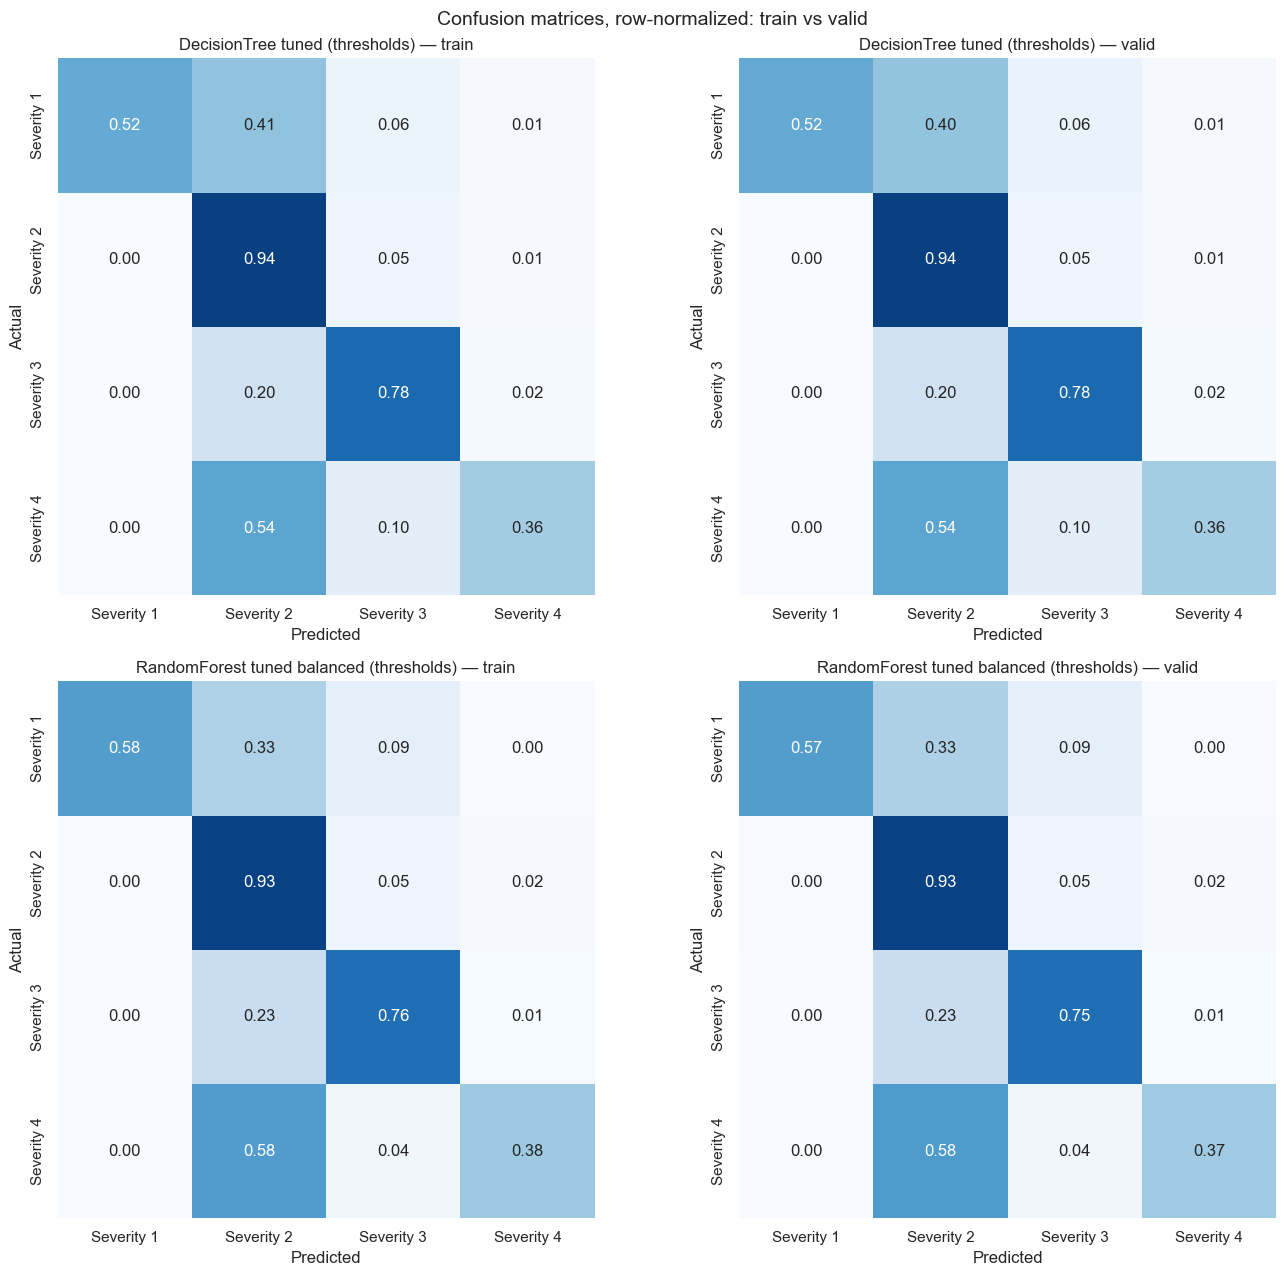

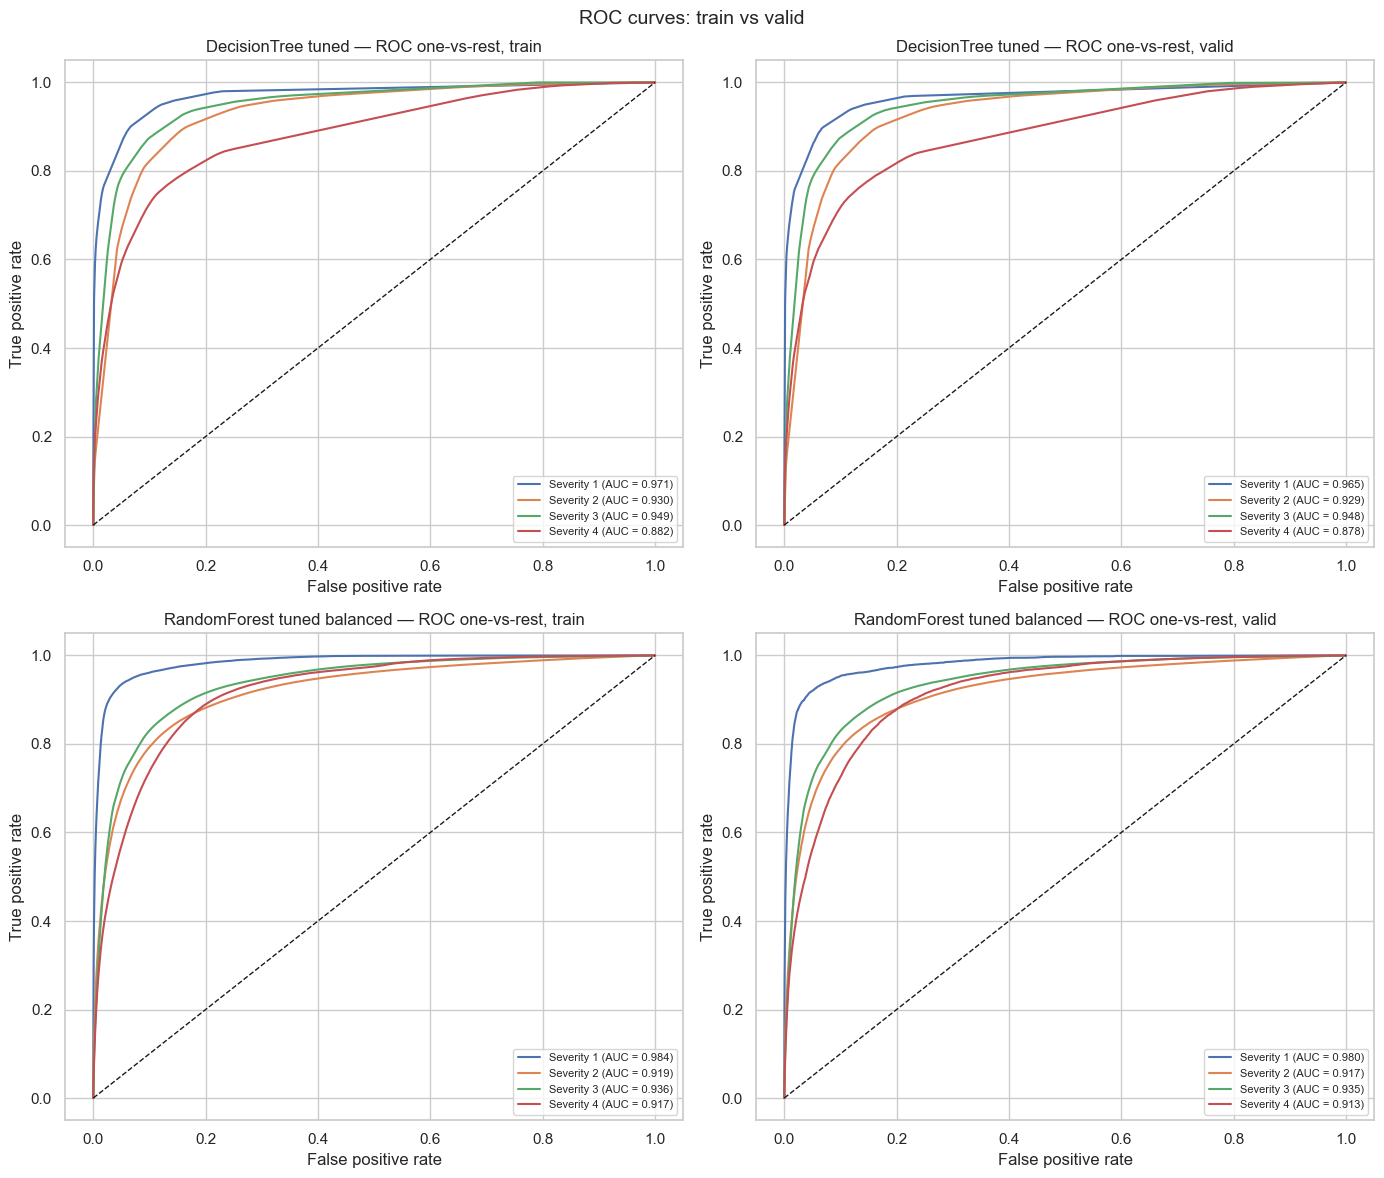

In [16]:
leader_preds = {(fam, split): final[fam].transform(data[split]) for fam in final for split in ("train", "valid")}
leader_cms = run_parallel(lambda key: confusion(leader_preds[key]), leader_preds)
leader_rocs = run_parallel(lambda key: roc_curves(leader_preds[key]), leader_preds)

fig, axes = plt.subplots(2, 2, figsize=(14, 13))
for i, fam in enumerate(final):
    for j, split in enumerate(("train", "valid")):
        plot_confusion(leader_cms[(fam, split)], axes[i, j], f"{LEADERS[fam]} (thresholds) — {split}")
fig.suptitle("Confusion matrices, row-normalized: train vs valid", fontsize=14)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
for i, fam in enumerate(final):
    for j, split in enumerate(("train", "valid")):
        plot_roc(leader_rocs[(fam, split)], axes[i, j], f"{LEADERS[fam]} — ROC one-vs-rest, {split}")
fig.suptitle("ROC curves: train vs valid", fontsize=14)
plt.tight_layout()
plt.show()

## Етап 5. Фінальне оцінювання на тестовій вибірці

In [17]:
test_preds = {fam: final[fam].transform(data["test"]) for fam in final}
results_test = pd.DataFrame(run_parallel(lambda fam: evaluate(test_preds[fam]), final)).T
results_test.index = [f"{LEADERS[fam]} (thresholds)" for fam in results_test.index]
results_test.T.round(4)

,DecisionTree tuned (thresholds),RandomForest tuned balanced (thresholds)
Accuracy,0.8905,0.8814
Balanced accuracy,0.6448,0.6563
Precision Severity 1,0.7190,0.5821
Precision Severity 2,0.9319,0.9245
Precision Severity 3,0.7795,0.7672
Precision Severity 4,0.3947,0.4075
Recall Severity 1,0.4999,0.5643
Recall Severity 2,0.9377,0.9302
Recall Severity 3,0.7791,0.7565
Recall Severity 4,0.3625,0.3742


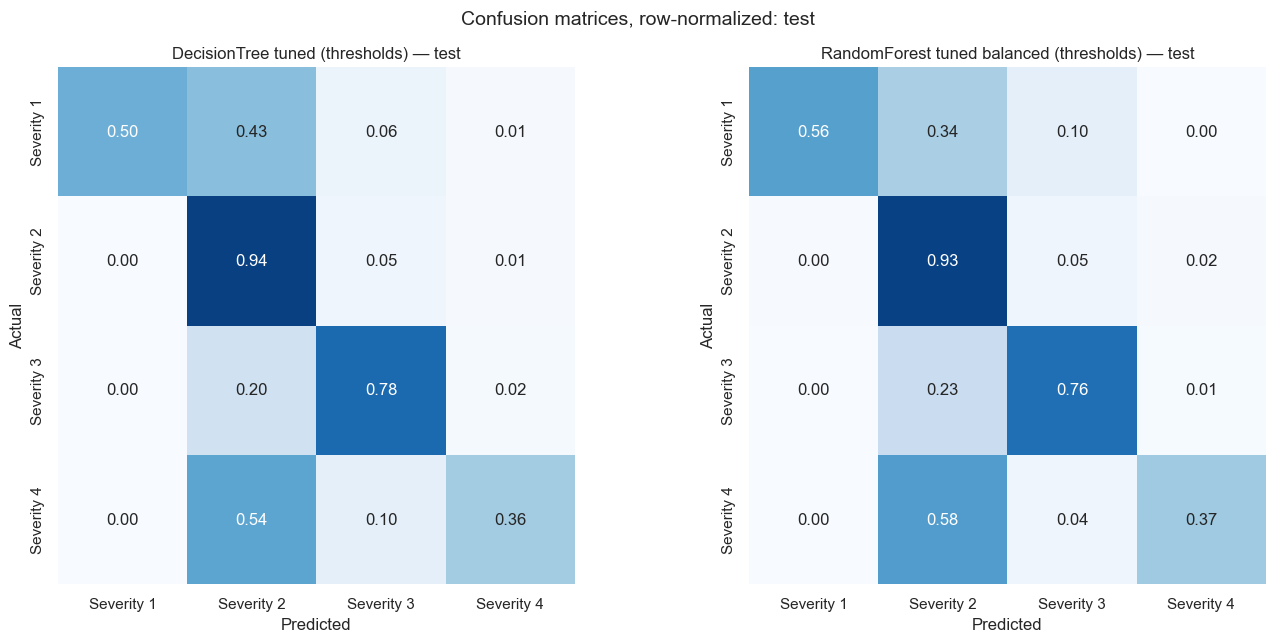

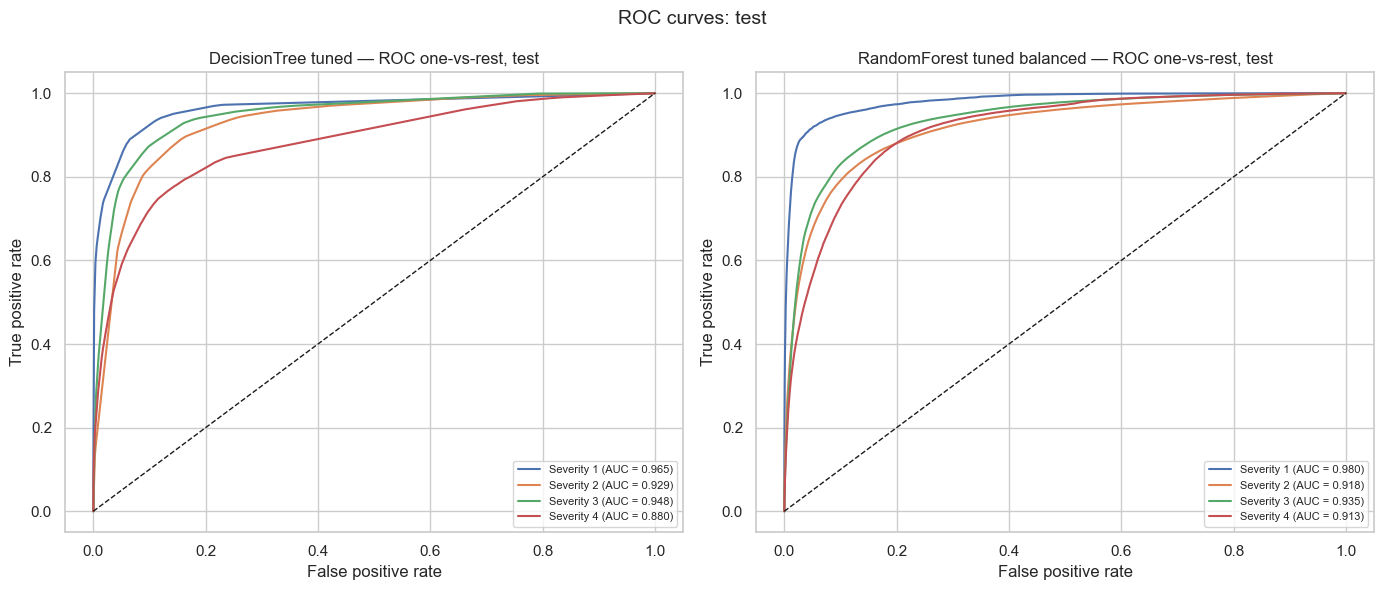

In [18]:
test_cms = run_parallel(lambda fam: confusion(test_preds[fam]), final)
test_rocs = run_parallel(lambda fam: roc_curves(test_preds[fam]), final)

fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))
for ax, fam in zip(axes, final):
    plot_confusion(test_cms[fam], ax, f"{LEADERS[fam]} (thresholds) — test")
fig.suptitle("Confusion matrices, row-normalized: test", fontsize=14)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, fam in zip(axes, final):
    plot_roc(test_rocs[fam], ax, f"{LEADERS[fam]} — ROC one-vs-rest, test")
fig.suptitle("ROC curves: test", fontsize=14)
plt.tight_layout()
plt.show()

## Етап 6. SHAP-аналіз та інтерпретованість

Стратифікований семпл ~3 000 записів test. `shap.TreeExplainer` читає дерева Spark-моделі напряму й пояснює ймовірності класів; пороги на ці пояснення не впливають.

In [19]:
shap_frac = min(1.0, SHAP_ROWS / N_ROWS["test"])
shap_rows = (data["test"].sampleBy("label", {float(k): shap_frac for k in CLASSES}, seed=SEED)
             .select("label", vector_to_array("features").alias("x")).toPandas())
X_shap = pd.DataFrame(np.stack(shap_rows["x"].to_numpy()), columns=FEATURES)
print(f"SHAP sample: {len(X_shap):,} rows, per class: "
      f"{dict(zip(CLASS_NAMES, shap_rows['label'].value_counts().sort_index().tolist()))}")

shap_values = {}
for fam, model in final.items():
    t0 = time.time()
    shap_values[fam] = shap.TreeExplainer(model)(X_shap)
    print(f"{LEADERS[fam]}: {time.time() - t0:.0f} s, SHAP values {shap_values[fam].values.shape}")

SHAP sample: 1,044 rows, per class: {'Severity 1': 6, 'Severity 2': 827, 'Severity 3': 184, 'Severity 4': 27}


/Users/yana.vyklyuk/Documents/GitHub/US-Accidents-spark-project/.venv/lib/python3.12/site-packages/shap/explainers/_tree.py:497: UserWarning: check_additivity requires us to run predictions which is not supported with spark, ignoring. Set check_additivity=False to remove this warning
  warnings.warn(


DecisionTree tuned: 11 s, SHAP values (1044, 244, 4)


RandomForest tuned balanced: 396 s, SHAP values (1044, 244, 4)


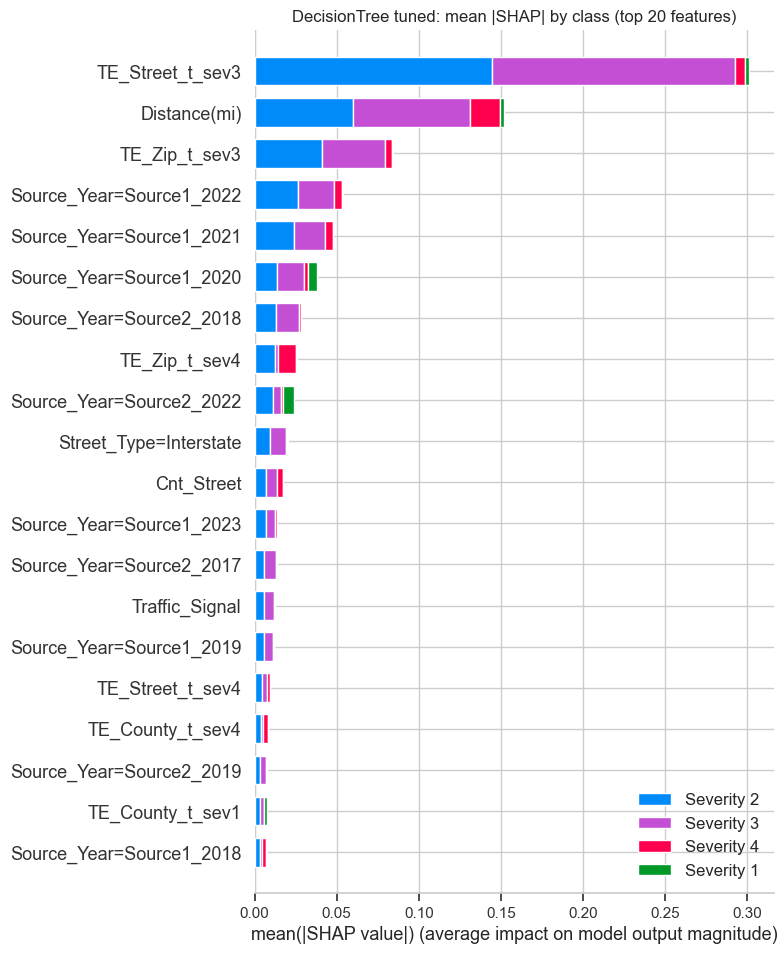

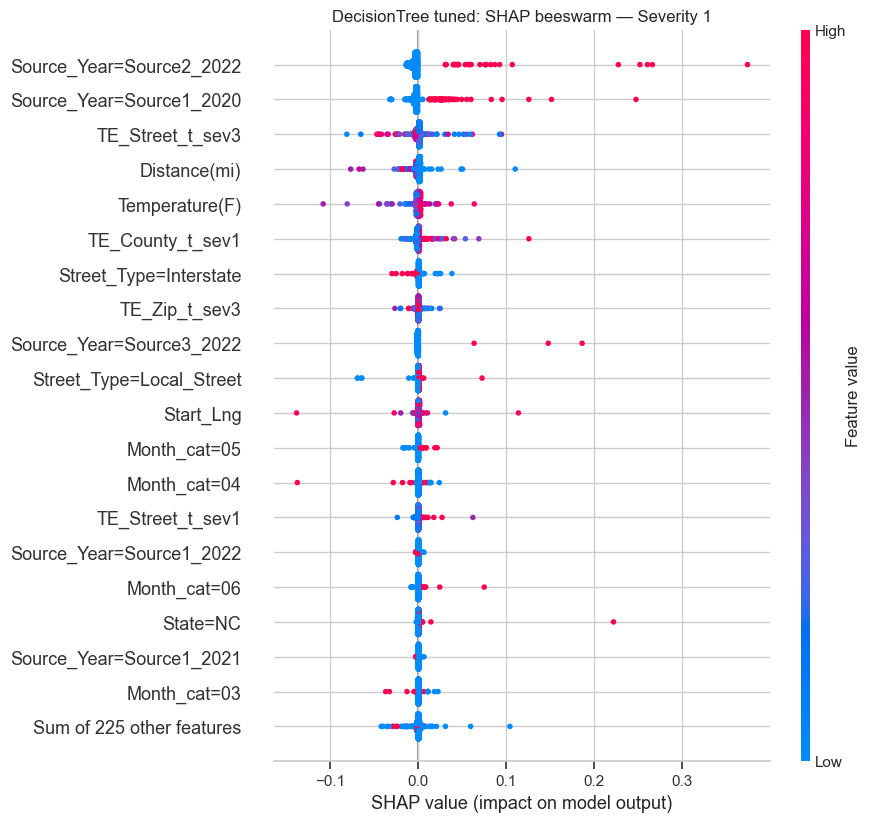

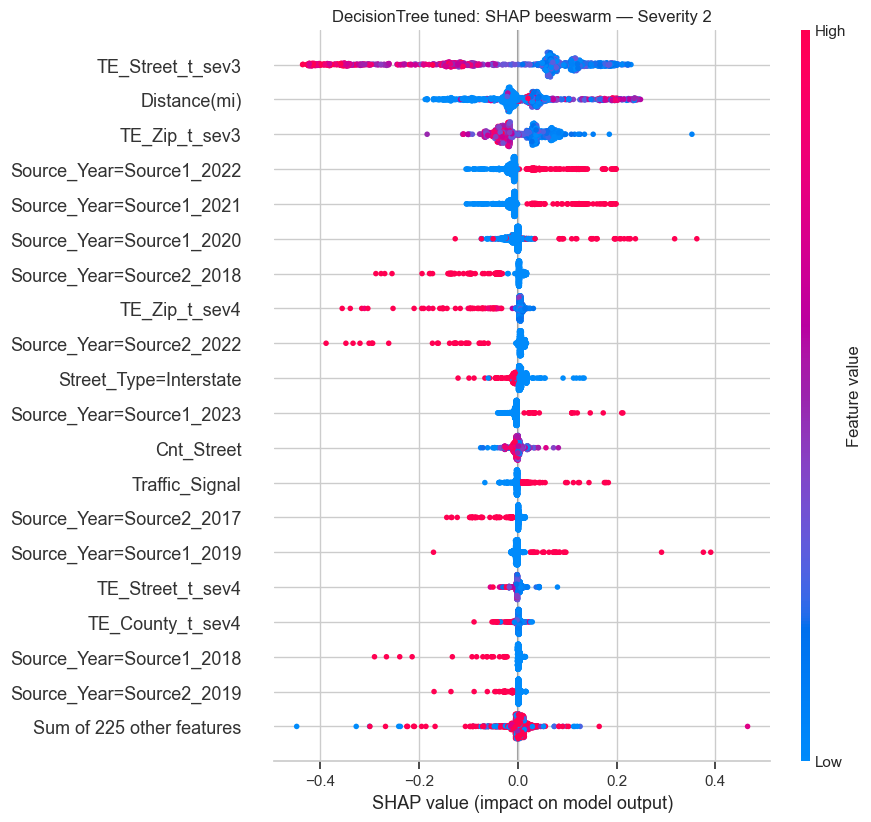

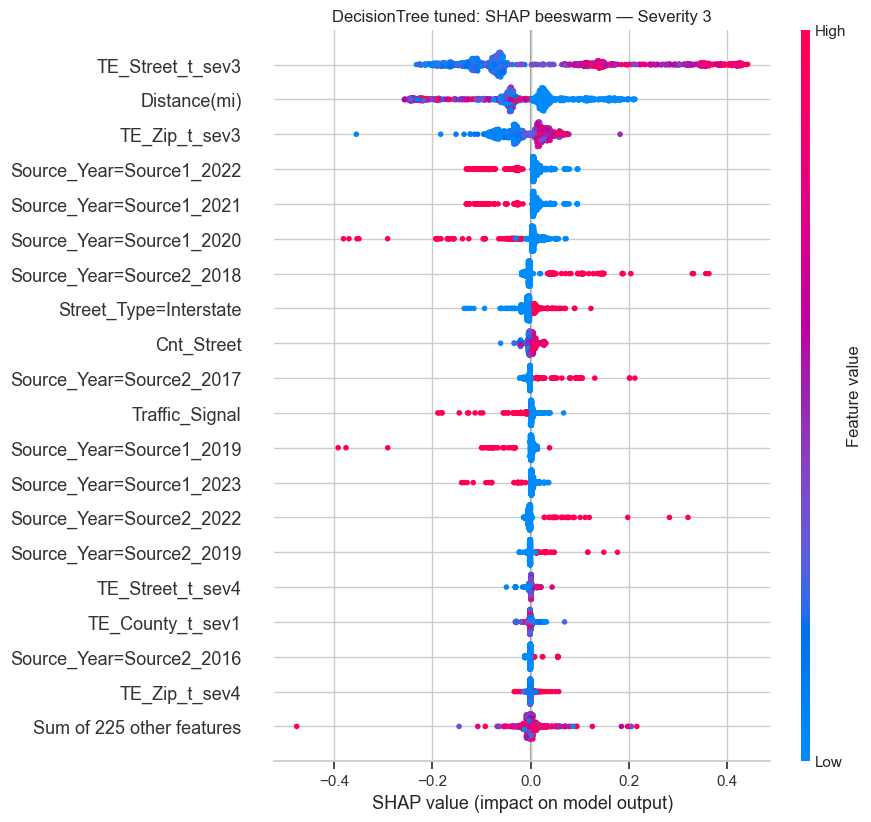

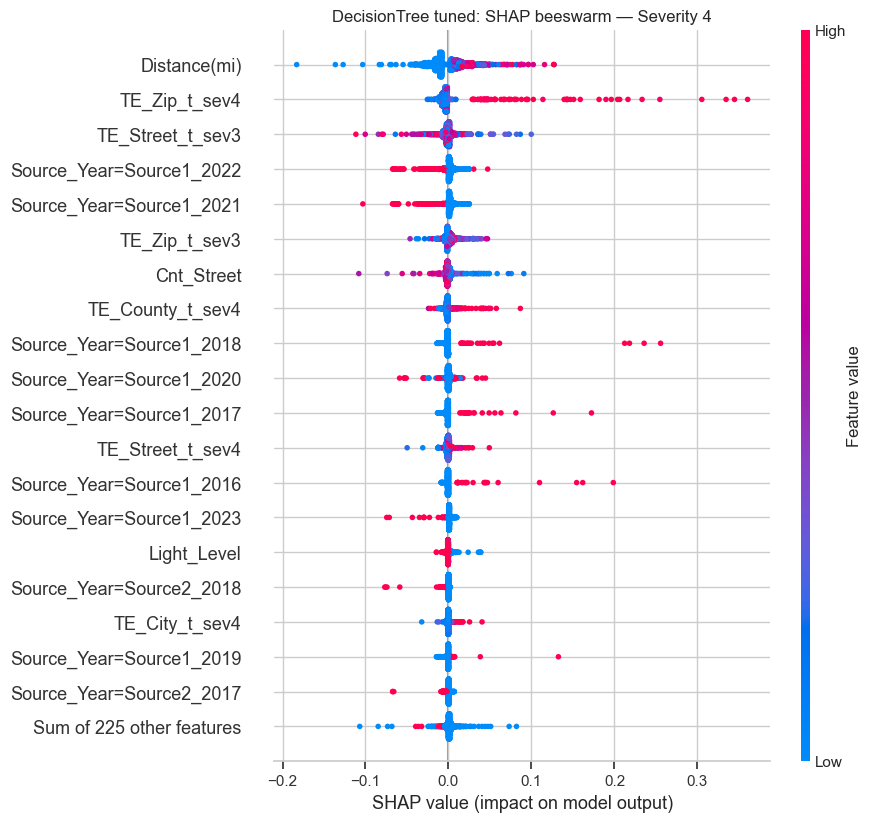

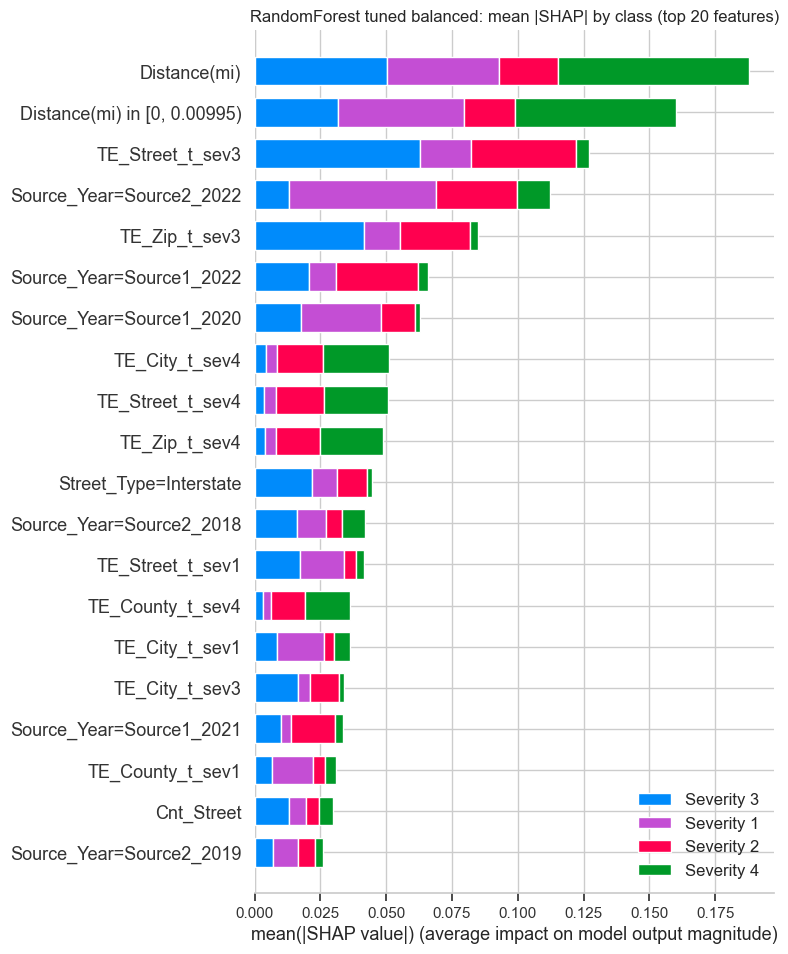

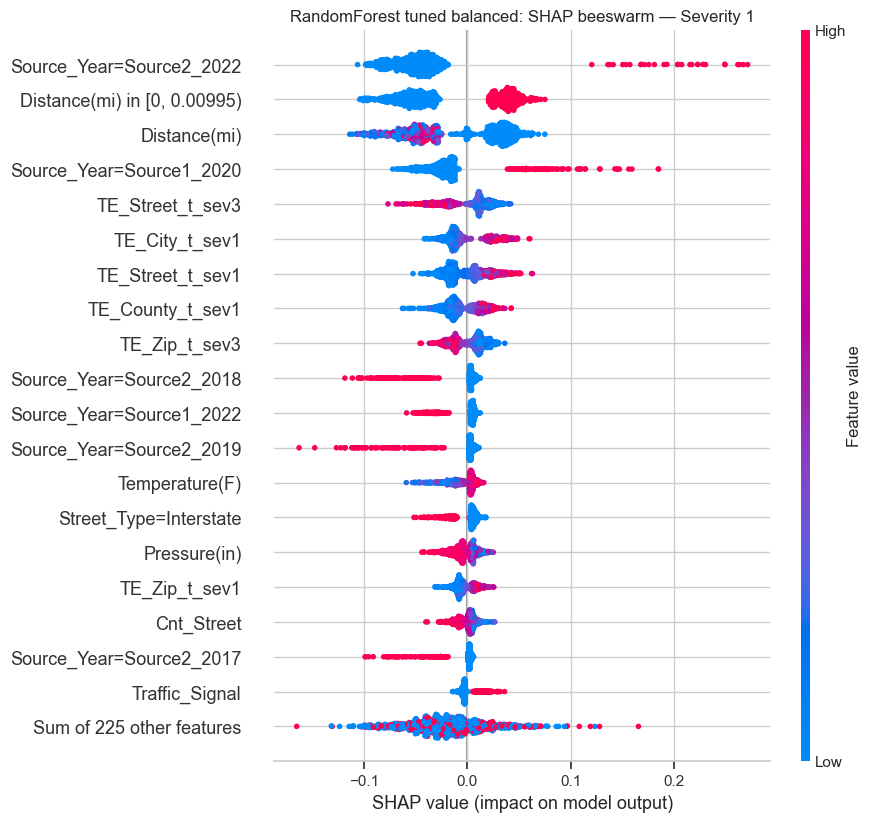

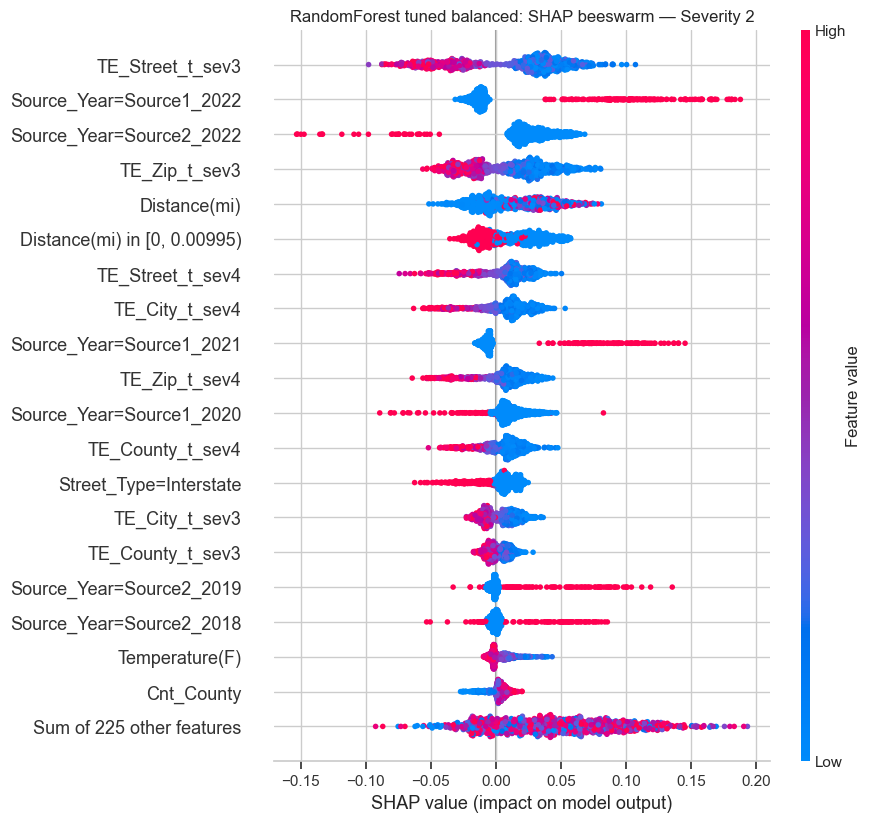

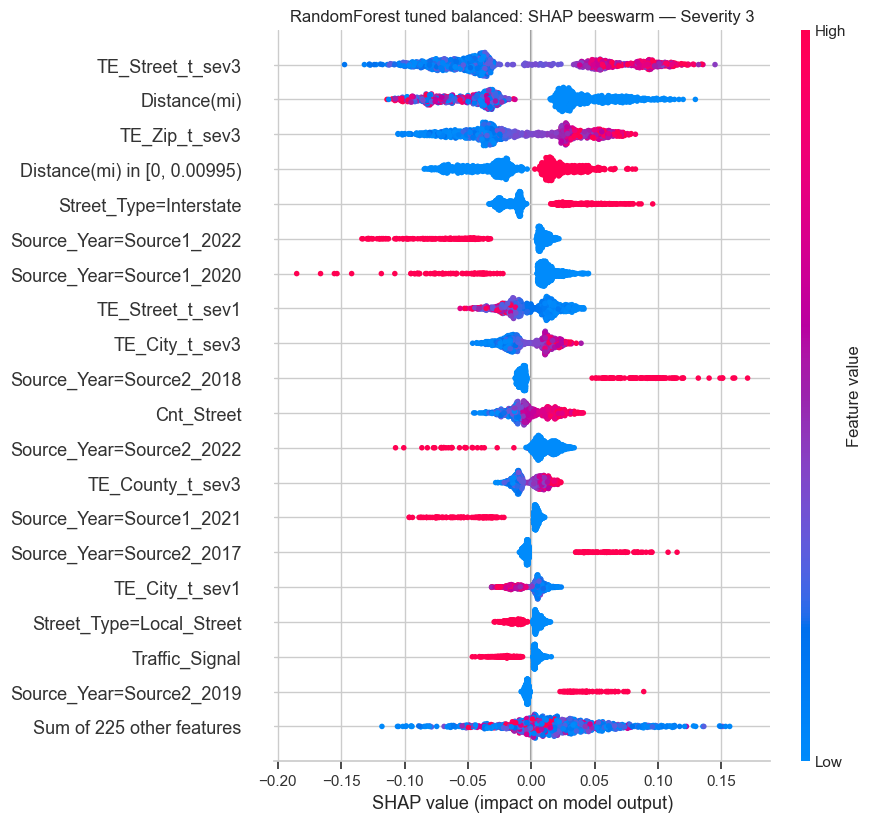

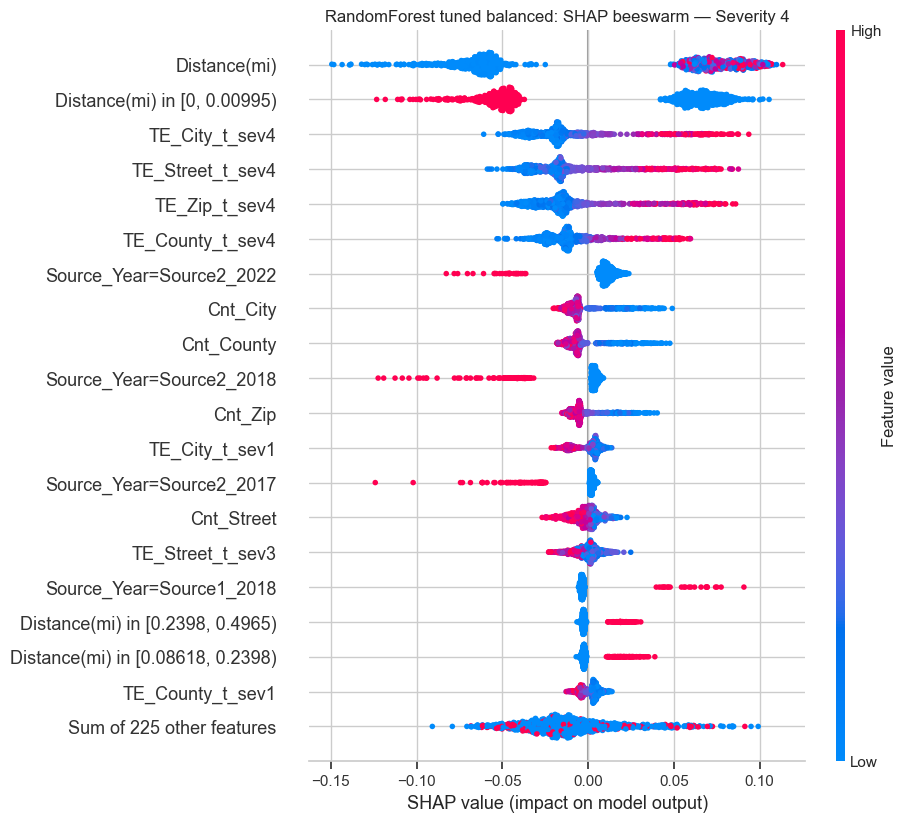

In [20]:
for fam, sv in shap_values.items():
    shap.summary_plot([sv.values[:, :, k] for k in CLASSES], X_shap, plot_type="bar", class_names=CLASS_NAMES,
                      max_display=20, show=False)
    plt.title(f"{LEADERS[fam]}: mean |SHAP| by class (top 20 features)")
    plt.show()
    for k in CLASSES:
        shap.plots.beeswarm(sv[:, :, k], max_display=20, show=False)
        plt.title(f"{LEADERS[fam]}: SHAP beeswarm — {CLASS_NAMES[k]}")
        plt.show()

## Збереження лідерів

In [21]:
for fam, model in final.items():
    path = MODELS_DIR / f"{TASK}_yv_{fam}"
    model.write().overwrite().save(str(path))
    info = {"variant": LEADERS[fam], "thresholds": list(model.getThresholds()),
            "params": {p.name: v for p, v in model.extractParamMap().items()},
            "features": FEATURES, "classes": "label 0..3 = Severity 1..4"}
    path.with_suffix(".json").write_text(json.dumps(info, indent=2, default=str), encoding="utf-8")
    print(f"Saved {LEADERS[fam]} -> {path}")

Saved DecisionTree tuned -> /Users/yana.vyklyuk/Documents/GitHub/US-Accidents-spark-project/data/models/classification_yv_DecisionTree


Saved RandomForest tuned balanced -> /Users/yana.vyklyuk/Documents/GitHub/US-Accidents-spark-project/data/models/classification_yv_RandomForest


In [22]:
for df in [*data.values(), tune]:
    df.unpersist()
spark.stop()